# Script to train model on entire development dataset

This script trains chosen model on entrie development data. We then measure it's performance on withheld data.



In [1]:
import kagglehub

from pathlib import Path
from fastai.vision.all import *

from sklearn.model_selection import train_test_split
from sklearn.metrics import label_ranking_average_precision_score
from collections import Counter

import torch

import matplotlib.pyplot as plt
import zipfile
from contextlib import redirect_stdout
from google.colab import files as colab_files

import shutil

print(f'Finished loading packages')

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Finished loading packages


In [2]:
danielshanbalico_dog_emotion_path = kagglehub.dataset_download('danielshanbalico/dog-emotion')
print(danielshanbalico_dog_emotion_path)
mohitagarwal17_dog_img_path = kagglehub.dataset_download('mohitagarwal17/dog-img')
mohitagarwal17_dog_emotion_classifier_89_accuracy_other_default_1_path = kagglehub.model_download('mohitagarwal17/dog-emotion-classifier-89-accuracy/Other/default/1')

Using Colab cache for faster access to the 'dog-emotion' dataset.
/kaggle/input/dog-emotion
Using Colab cache for faster access to the 'dog-img' dataset.


In [3]:
searches = 'angry','happy','relaxed','sad'
path = Path(danielshanbalico_dog_emotion_path)

# Load the CSV containing the selected filenames
csv_url = "https://raw.githubusercontent.com/Sincanator/Group-Sprint-2/refs/heads/main/Data/emotion_classifier_data_from_kaggle/development_split.csv"
df = pd.read_csv(csv_url)

# Create files list using only filenames in CSV
files = [path / filename for filename in df["filename"]]

print(f"Number of images in subset: {len(files)}")

Number of images in subset: 3600


In [4]:
# Create train test split
train_files = files

print(len(train_files))


# Checking the class distribution in data split
print("Training:", Counter(f.parent.name for f in train_files))



3600
Training: Counter({'relaxed': 900, 'happy': 900, 'angry': 900, 'sad': 900})


In [5]:
# TEST files
test_csv_url = "https://raw.githubusercontent.com/Sincanator/Group-Sprint-2/refs/heads/main/Data/emotion_classifier_data_from_kaggle/final_test_split.csv"
df = pd.read_csv(test_csv_url)

# Create files list using only filenames in CSV
test_files = [path / filename for filename in df["filename"]]

print(f"Number of images in subset: {len(test_files)}")


Number of images in subset: 400


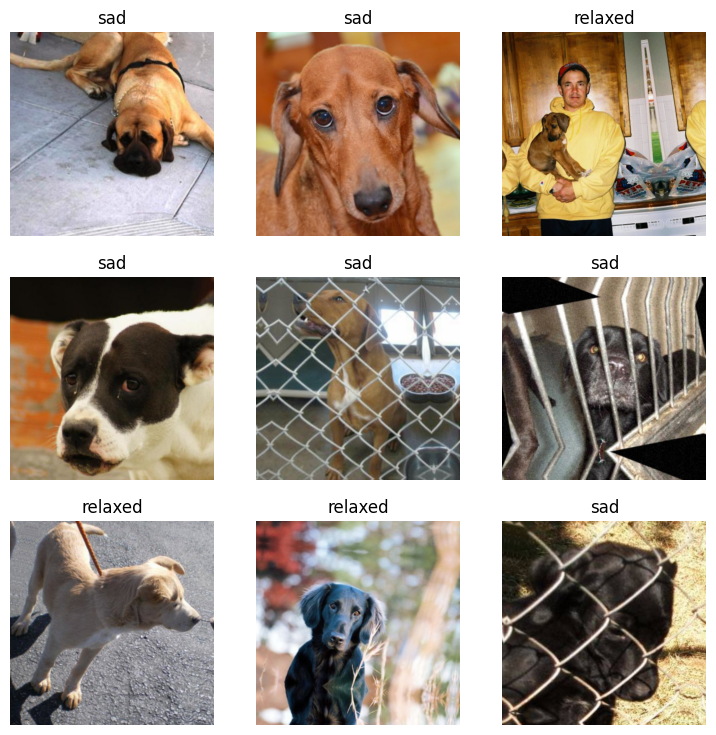

In [6]:
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=noop,
    splitter=RandomSplitter(valid_pct=0.2, seed=42), # generates validation set 20% of train
    get_y=parent_label, # gets labesl
    item_tfms=[Resize(400, method='pad', pad_mode='reflection')], # resizes to 400 x 400 with padding using reflection padding mode. Done since squishing features may make harder to read expression
    batch_tfms=aug_transforms(mult=1.0,
                              do_flip=True,
                              flip_vert=False,
                              max_rotate=15.0,
                              min_zoom=1.0,
                              max_zoom=1.1,
                              max_lighting=0.2,
                              max_warp=0.1) # augmentation done on the fly and in place rather than statically, changes for each training epoch to reduce overfitting
).dataloaders(train_files, bs=16) # batch size of 16 is changed from 56 since crahsed t4gpu usage limits, train data is of size 4000 * 0.85 * 0.8 = 2720 (2720 / 40 = 68)

dls.show_batch()

learn = vision_learner(dls,

                       #######################
                       ### MODEL TO CHANGE ###
                       ######## BELOW ########
                       #######################

                       densenet121,
                       opt_func=Adam,

                       loss_func=CrossEntropyLossFlat(), #looked to replace normal cross entropy with label smoothed due to some dodgy labels, but didnt improve accuracy
                       metrics=error_rate,
                       wd=0.01).to_fp16() # using transfer learning from pretrained alexnet.





In [7]:
if torch.cuda.is_available():
    print("GPU available:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("No GPU available. Using CPU.")



GPU available: Tesla T4
CUDA version: 13.0


<div></div>

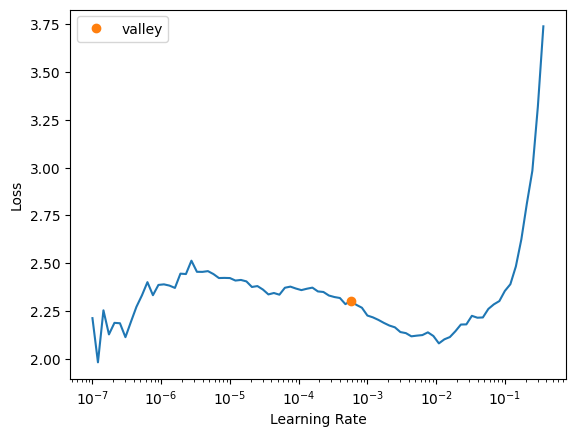

In [8]:
lrs = learn.lr_find() #note the valley here is conservative and i have found better results by using a more agressive lr

epoch,train_loss,valid_loss,error_rate,time
0,1.365533,0.932644,0.288889,01:02


epoch,train_loss,valid_loss,error_rate,time
0,0.823842,0.617401,0.237500,01:11
1,0.702026,0.579965,0.202778,01:13
2,0.456383,0.409889,0.151389,01:15
3,0.255527,0.322418,0.111111,01:13


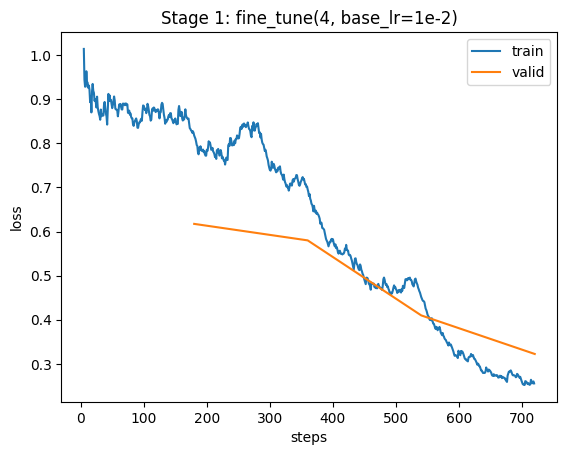

epoch,train_loss,valid_loss,error_rate,time
0,0.246709,0.333551,0.123611,01:18
1,0.222054,0.324798,0.122222,01:15
2,0.139872,0.293069,0.104167,01:13
3,0.097817,0.285035,0.095833,01:12


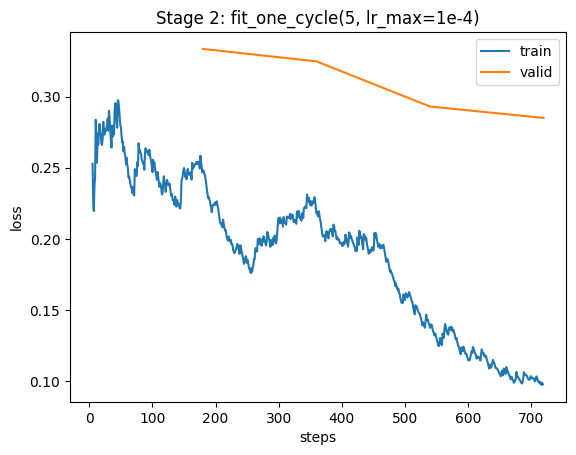

epoch,train_loss,valid_loss,error_rate,time
0,0.086082,0.282238,0.095833,01:17
1,0.096058,0.273591,0.094444,01:12


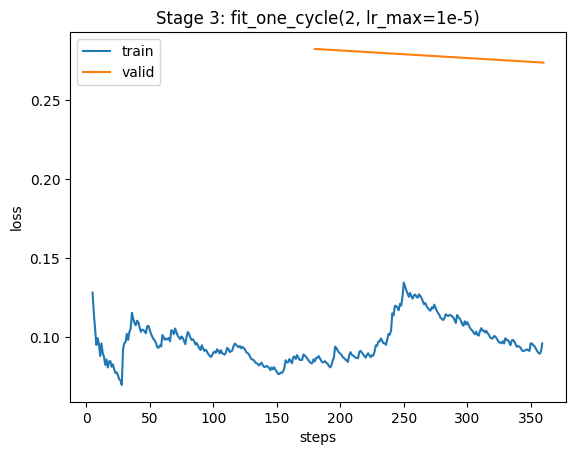

In [9]:
learn.fine_tune(4, base_lr=1e-2) # finetune is built in to tune pretrained models, it uses adaptive lr. for 4 epochs trains class head, then whole model for 1 epoch
learn.recorder.plot_loss()
plt.title("Stage 1: fine_tune(4, base_lr=1e-2)")
plt.show()

learn.unfreeze()

learn.fit_one_cycle(4, lr_max=1e-4)
learn.recorder.plot_loss()
plt.title("Stage 2: fit_one_cycle(4, lr_max=1e-4)")
plt.show()

learn.fit_one_cycle(2, lr_max=1e-5)
learn.recorder.plot_loss()
plt.title("Stage 3: fit_one_cycle(2, lr_max=1e-5)")
plt.show()

#learn.fit_one_cycle(1, lr_max=1e-7)
#learn.recorder.plot_loss()
#plt.title("Stage 4: fit_one_cycle(1, lr_max=1e-6)")
#plt.show()

In [10]:
test_dl = dls.test_dl(test_files, with_labels=True)
loss, err = learn.validate(dl=test_dl)
accuracy = (1-err)*100
print(f"Test Images: {len(test_files)}")
print(f"Correct Predictions: {round(accuracy*len(test_files)/100)}")
print(f"Incorrect Predictions: {len(test_files)-round(accuracy*len(test_files)/100)}")
print(f"Accuracy: {accuracy:.2f}%")

Test Images: 400
Correct Predictions: 357
Incorrect Predictions: 43
Accuracy: 89.25%


In [11]:
next(learn.model.parameters()).device

##############################
### PUT MODEL NAME IN PATH ###
##############################

save_path = Path('/content/dog_emotion_model_resnet50_final.pkl')

# Export the trained model
learn.cpu()
learn.export(save_path)

next(learn.model.parameters()).device

##############################
### PUT MODEL NAME IN PATH ###
##############################

save_path = Path('/content/dog_emotion_model_resnet50_final.pkl')

# Export the trained model
learn.cpu()
learn.export(save_path)

              precision    recall  f1-score   support

       angry       0.96      0.89      0.92       100
       happy       0.95      0.95      0.95       100
     relaxed       0.78      0.90      0.84       100
         sad       0.90      0.83      0.86       100

    accuracy                           0.89       400
   macro avg       0.90      0.89      0.89       400
weighted avg       0.90      0.89      0.89       400



results of form true | predicted


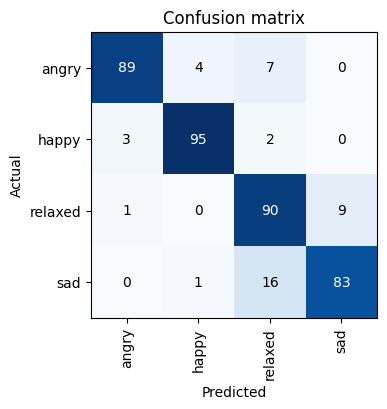

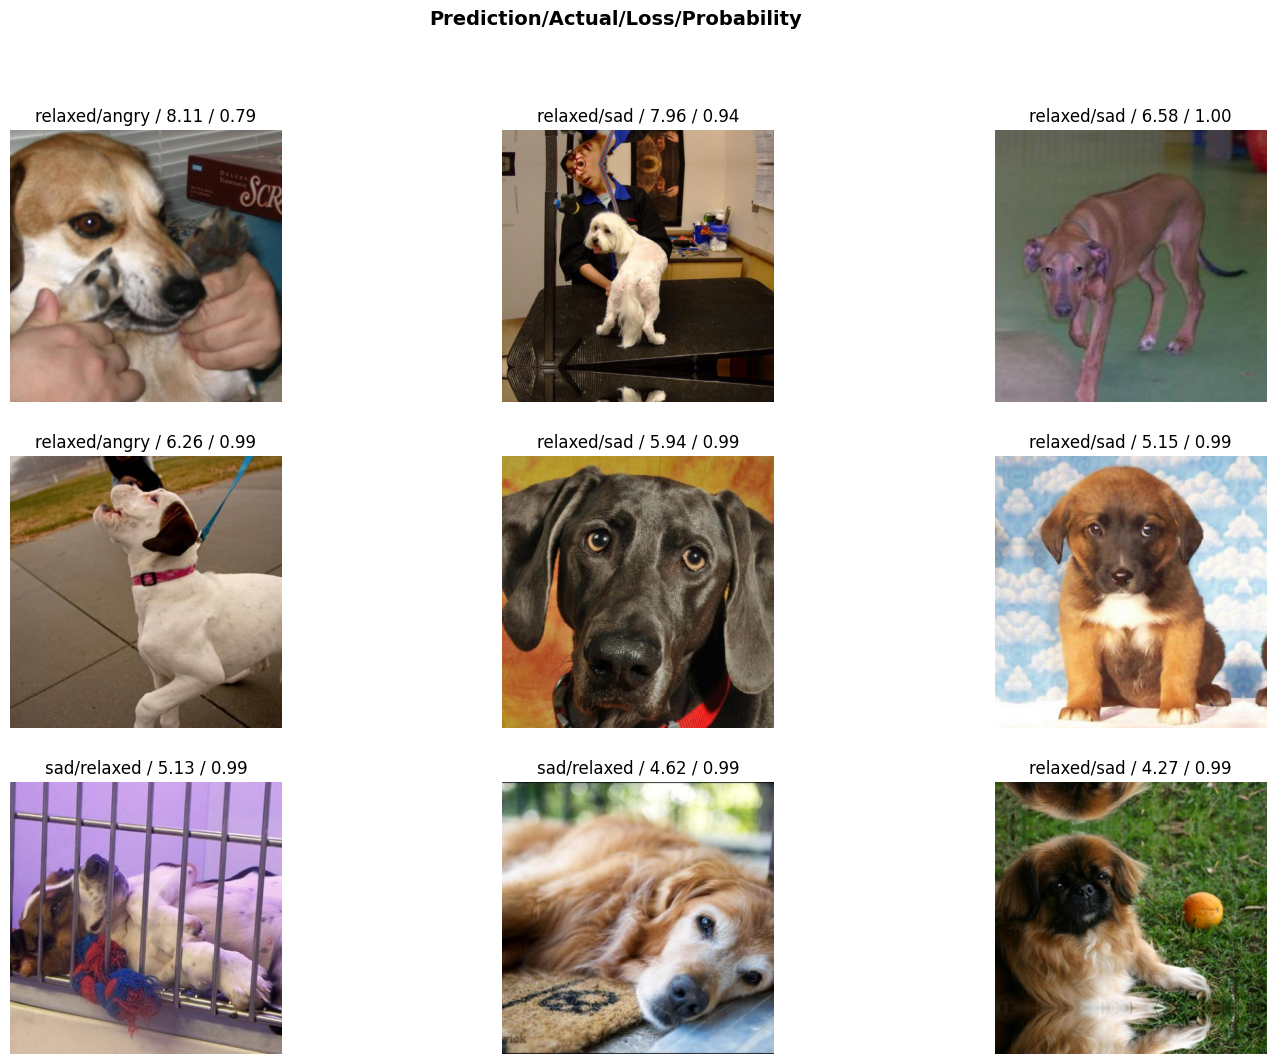

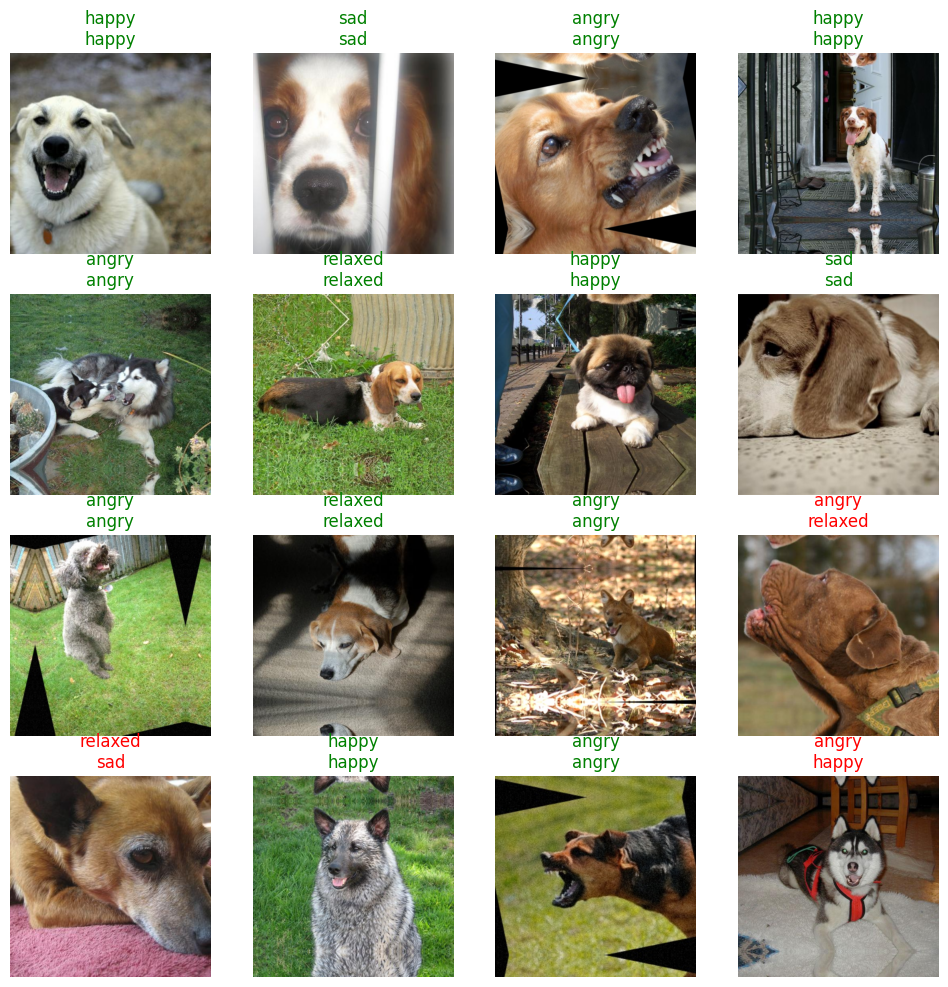

In [12]:
interp = ClassificationInterpretation.from_learner(learn, dl=test_dl)
interp.print_classification_report()
interp.plot_confusion_matrix(figsize=(4,4))
interp.plot_top_losses(9, figsize=(18,12))

print(f'results of form true | predicted')
interp.show_results(idxs=list(range(16)))

In [13]:
# Create results folder

#############################
### CHANGE DIRECTORY NAME ###
#############################
results_dir = Path('/content/densenet121_VERY_FINAL_results')
results_dir.mkdir(exist_ok=True)

# 1. Copy exported model into results folder
shutil.copy(save_path, results_dir / save_path.name)

# 2. Save confusion matrix
interp.plot_confusion_matrix(figsize=(4, 4))
plt.savefig(results_dir / 'confusion_matrix.png',
            bbox_inches='tight', dpi=200)
plt.close('all')

# 3. Save top 9 losses
interp.plot_top_losses(9, figsize=(10, 7))
plt.savefig(results_dir / 'top_losses.png',
            bbox_inches='tight', dpi=200)
plt.close('all')

# 4. Save classification report
with open(results_dir / 'classification_report.txt', 'w') as f:
    with redirect_stdout(f):
        interp.print_classification_report()

# 5. Save 16 example predictions
interp.show_results(idxs=list(range(16)))
plt.savefig(results_dir / 'example_predictions.png',
            bbox_inches='tight', dpi=200)
plt.close('all')

# 6. Create ZIP
zip_path = Path('/content/densenet121_VERY_FINAL_results.zip')

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for file in results_dir.iterdir():
        if file.is_file():
            zipf.write(file, arcname=file.name)

# 7. Download
colab_files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>